# 02 – Modélisation et prévisions

Objectif : prévoir le total hebdomadaire des ventes du bonnet (55 magasins) sur les 40 semaines du test.
Nous testons deux modèles par étape, du plus simple au plus complexe, pour vérifier si la complexité apporte un gain réel.

| Étape | Modèle 1 | Modèle 2 |
|---|---|---|
| 2. Baselines | Seasonal naive | Seasonal naive × `n_stores` |
| 3. Méthodes classiques | ARIMA | SARIMAX |
| 4. Machine learning | Random Forest | XGBoost |
| 5. Deep learning simple | MLP | LSTM |
| 6. Deep learning avancé | TFT | N-HiTS |

Tous les modèles sont comparés sur le même fold de validation (EDA, section 6) avec la MSE, la métrique du Kaggle.

## 1. Préparation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)

DATA_DIR = Path('../centrale-lille-decathlon-forecast-project-10-2026')

train = pd.read_csv(DATA_DIR / 'train.csv', parse_dates=['date'])
test = pd.read_csv(DATA_DIR / 'test.csv', parse_dates=['date'])
sample_sub = pd.read_csv(DATA_DIR / 'submission.csv')

### 1.1 Série hebdomadaire

Nous travaillons sur le total hebdomadaire, car c'est la cible de la compétition. Les semaines absentes du train valent 0,
puisqu'une ligne n'existe que si le magasin a vendu. `n_stores` est gardé car il est connu aussi sur le test.

In [2]:
def weekly(df):
    agg = df.groupby('date').agg(n_stores=('bu', 'size'), week_id=('week_id', 'first'))
    if 'sales_quantity' in df:
        agg['sales'] = df.groupby('date').sales_quantity.sum()
    return agg

w_train, w_test = weekly(train), weekly(test)
full_idx = pd.date_range(w_train.index.min(), w_test.index.max(), freq='W-SUN')
w = pd.concat([w_train, w_test]).reindex(full_idx)
w.index.name = 'date'

is_train = w.index <= train.date.max()
w.loc[is_train, ['sales', 'n_stores']] = w.loc[is_train, ['sales', 'n_stores']].fillna(0)
w['n_stores'] = w['n_stores'].fillna(0).astype(int)
# week_id Decathlon = semaine ISO du lendemain (la semaine commence le dimanche)
iso = (w.index + pd.Timedelta(days=1)).isocalendar()
w['week_id'] = (iso.year * 100 + iso.week).values

hist = w[is_train].copy()          # tout l'historique connu
future = w[~is_train].copy()       # 40 semaines à prévoir
assert (future.week_id.values == sample_sub.ID.values).all()
print(f'Historique : {len(hist)} semaines | à prévoir : {len(future)} semaines')
w.tail()

Historique : 102 semaines | à prévoir : 40 semaines


,n_stores,week_id,sales
date,,,
2024-04-28,2,202418,NaN
2024-05-05,3,202419,NaN
2024-05-12,2,202420,NaN
2024-05-19,1,202421,NaN
2024-05-26,2,202422,NaN


### 1.2 Fold de validation

Pour éviter le *future leakage*, le fold reproduit la situation du test : entraînement jusqu'au 21/08/2022,
prévision des 40 semaines suivantes.

In [3]:
VAL_START = pd.Timestamp('2022-08-28')
H = 40
val_train = hist[hist.index < VAL_START]
val_future = hist[hist.index >= VAL_START].iloc[:H]
y_val = val_future.sales
print('Train :', val_train.index[0].date(), '→', val_train.index[-1].date(), f'({len(val_train)} sem.)')
print('Val   :', val_future.index[0].date(), '→', val_future.index[-1].date(), f'({len(val_future)} sem.)')

Train : 2021-09-12 → 2022-08-21 (50 sem.)
Val   : 2022-08-28 → 2023-05-28 (40 sem.)


### 1.3 Fonctions communes

Chaque modèle est une fonction `forecast(past, fut)`, évaluée à l'identique sur le fold de validation.
Ainsi, tous les modèles sont comparés exactement dans les mêmes conditions.

In [4]:
results = {}       # métriques de validation par modèle
val_preds = {}     # prévisions de validation par modèle

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_true - y_pred
    return {'MSE': np.mean(err ** 2), 'RMSE': np.sqrt(np.mean(err ** 2)),
            'MAE': np.mean(np.abs(err)), 'WAPE': np.abs(err).sum() / np.abs(y_true).sum()}

def evaluate(name, forecast):
    """Entraîne sur le fold, prévoit les 40 semaines de validation, enregistre et affiche les métriques."""
    pred = forecast(val_train, val_future.drop(columns='sales')).clip(lower=0)
    val_preds[name] = pred
    results[name] = metrics(y_val, pred)
    print(name, '|', ' | '.join(f'{k} = {v:,.3f}' if k == 'WAPE' else f'{k} = {v:,.0f}' for k, v in results[name].items()))
    return pred

def plot_val(names, title='Validation: forecast vs actual'):
    fig, ax = plt.subplots()
    ax.plot(y_val.index, y_val, color='k', lw=2, label='Actual')
    for n in names:
        ax.plot(val_preds[n].index, val_preds[n], marker='.', label=n)
    ax.set_title(title); ax.set_ylabel('units sold'); ax.legend(); plt.show()

def results_table():
    return pd.DataFrame(results).T.sort_values('MSE').style.format(
        {'MSE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAE': '{:,.0f}', 'WAPE': '{:.1%}'})

## 2. Baselines

Modèles sans apprentissage qui servent de référence : un modèle plus complexe n'a d'intérêt que s'il fait mieux qu'eux.

### 2.1 Seasonal naive

Le produit est très saisonnier, donc la référence la plus naturelle est de copier la même semaine de l'année précédente :
$\hat{y}_t = y_{t-52}$.

In [5]:
def seasonal_naive(past, fut):
    lag = fut.index - pd.Timedelta(weeks=52)
    return pd.Series(past.sales.reindex(lag).fillna(0).values, index=fut.index)

evaluate('Seasonal naive', seasonal_naive);

Seasonal naive | MSE = 409,124 | RMSE = 640 | MAE = 392 | WAPE = 0.428


### 2.2 Seasonal naive ajusté par `n_stores`

`n_stores` est connu sur le test : nous multiplions les ventes moyennes par magasin actif de l'année précédente par le
nombre de magasins actifs de la semaine, pour suivre un démarrage de saison plus tôt ou plus tard :
$\hat{y}_t = n\_stores_t \times y_{t-52} / n\_stores_{t-52}$.

In [6]:
def seasonal_naive_stores(past, fut):
    lag = fut.index - pd.Timedelta(weeks=52)
    per_store = (past.sales / past.n_stores.replace(0, np.nan)).reindex(lag).fillna(0)
    return pd.Series(fut.n_stores.values * per_store.values, index=fut.index)

evaluate('Seasonal naive × n_stores', seasonal_naive_stores);

Seasonal naive × n_stores | MSE = 416,524 | RMSE = 645 | MAE = 395 | WAPE = 0.432


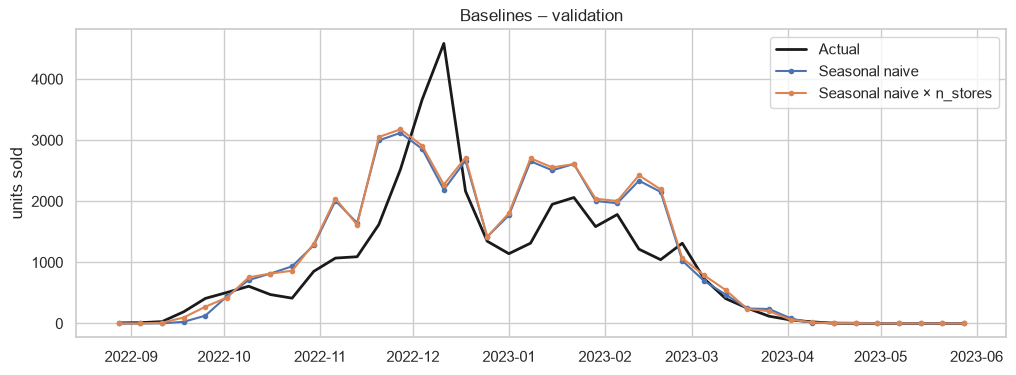

,MSE,RMSE,MAE,WAPE
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%


In [7]:
plot_val(['Seasonal naive', 'Seasonal naive × n_stores'], 'Baselines – validation')
results_table()

### 2.3 Conclusion

Les deux baselines sont équivalentes (MSE ≈ 409 000 et ≈ 417 000). L'ajustement par `n_stores` n'apporte rien, car
`n_stores` vaut ≈ 55 en pleine saison les deux années. L'erreur vient surtout du pic : copier 2021-22 place le pic
fin novembre alors qu'en 2022-23 il a lieu mi-décembre et plus haut.

## 3. Méthodes classiques

Les modèles sont ajustés sur `log1p(sales)` pour stabiliser la variance (pics de plusieurs milliers contre 0 en été),
puis ramenés à l'échelle d'origine avec `expm1`.

In [8]:
import itertools
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings('ignore', module='statsmodels')

### 3.1 ARIMA

d = 1 d'après les tests ADF/KPSS de l'EDA. p et q (de 0 à 2) sont choisis par AIC, qui récompense le bon ajustement
et pénalise le nombre de paramètres.

In [9]:
def arima_aic_grid(y, d=1, max_p=2, max_q=2):
    rows = []
    for p, q in itertools.product(range(max_p + 1), range(max_q + 1)):
        try:
            rows.append({'order': (p, d, q), 'AIC': ARIMA(y, order=(p, d, q)).fit().aic})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

def arima_forecast(past, fut):
    y = np.log1p(past.sales.values)
    order = arima_aic_grid(y).order[0]
    model = ARIMA(y, order=order).fit()
    return pd.Series(np.expm1(model.forecast(len(fut))), index=fut.index)

display(arima_aic_grid(np.log1p(val_train.sales.values)).head())
evaluate('ARIMA', arima_forecast);

,order,AIC
0,"(1, 1, 1)",107.668065
1,"(1, 1, 2)",107.717223
2,"(2, 1, 1)",108.215800
3,"(2, 1, 0)",109.098770
4,"(2, 1, 2)",110.378400


ARIMA | MSE = 1,876,560 | RMSE = 1,370 | MAE = 907 | WAPE = 0.992


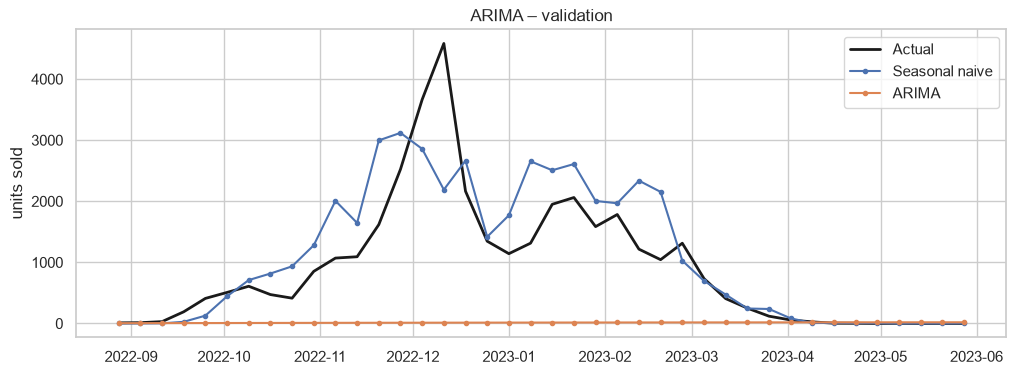

In [10]:
plot_val(['Seasonal naive', 'ARIMA'], 'ARIMA – validation')

L'ARIMA échoue (MSE ≈ 1,9 million) car il ne dispose d'aucune information saisonnière : il prolonge les ventes
quasi nulles de fin d'été et ne voit pas arriver l'hiver.

### 3.2 SARIMAX

Un SARIMA avec s = 52 exige au moins deux cycles complets, or le fold n'a que 50 semaines. Nous apportons donc la
saisonnalité par des variables exogènes :
- `log_stores`, car il est connu sur la période à prévoir ;
- des termes de Fourier annuels, pour une courbe saisonnière lisse ;
- `pre_xmas` (5 semaines avant Noël), pour l'effet Black Friday → Noël.

Nous utilisons d = 0 (AR(1) avec constante) et non d = 1, car avec d = 1 toute la prévision est ancrée sur la dernière
semaine observée, quasi nulle (voir le test de sensibilité). Le log des ventes est stationnaire (ADF p = 0,037), ce qui
justifie d = 0. Les exogènes sont choisies par AIC sur l'entraînement ; parmi les modèles à moins de 2 points du
meilleur, nous gardons le plus simple (K = 1 + `pre_xmas`).

In [11]:
def fourier_terms(idx, K, period=52.18):
    t = (idx - pd.Timestamp('2021-01-03')).days / 7
    return pd.DataFrame({f'{f}{k}': fn(2 * np.pi * k * t / period)
                         for k in range(1, K + 1) for f, fn in [('sin', np.sin), ('cos', np.cos)]}, index=idx)

def sarimax_exog(df, K=1, xmas=True):
    X = pd.DataFrame({'log_stores': np.log1p(df.n_stores)}, index=df.index)
    if K:
        X = X.join(fourier_terms(df.index, K))
    if xmas:
        days_to_xmas = np.array([(pd.Timestamp(year=d.year, month=12, day=25) - d).days for d in df.index])
        X['pre_xmas'] = ((days_to_xmas >= 0) & (days_to_xmas <= 35)).astype(int)
    return X

SARIMAX_ORDER, SARIMAX_TREND = (1, 0, 0), 'c'   # AR(1) + constante, d = 0

# Choix des variables exogènes par AIC (période d'entraînement du fold uniquement)
y_fold = np.log1p(val_train.sales.values)
aic_rows = [{'K Fourier': K, 'pre_xmas': xm,
             'AIC': SARIMAX(y_fold, exog=sarimax_exog(val_train, K, xm).values, order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False).aic}
            for K in [0, 1, 2] for xm in [False, True]]
display(pd.DataFrame(aic_rows).sort_values('AIC').round(1))

,K Fourier,pre_xmas,AIC
4,2,False,28.0
5,2,True,28.0
3,1,True,29.2
2,1,False,30.9
1,0,True,45.4
0,0,False,49.5


In [12]:
def sarimax_forecast(past, fut, K=1, xmas=True):
    model = SARIMAX(np.log1p(past.sales.values), exog=sarimax_exog(past, K, xmas).values,
                    order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False)
    pred = model.forecast(len(fut), exog=sarimax_exog(fut, K, xmas).values)
    return pd.Series(np.expm1(pred), index=fut.index)

evaluate('SARIMAX', sarimax_forecast);

# Diagnostic des résidus : test de Ljung-Box (H0 : résidus non autocorrélés = bruit blanc)
fit = SARIMAX(y_fold, exog=sarimax_exog(val_train).values, order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False)
display(acorr_ljungbox(fit.resid[1:], lags=[4, 8, 12]).round(3))
display(fit.summary().tables[1])

SARIMAX | MSE = 307,184 | RMSE = 554 | MAE = 317 | WAPE = 0.347


,lb_stat,lb_pvalue
4,6.098,0.192
8,13.012,0.111
12,21.707,0.041


,coef,std err,z,P>|z|,[0.025,0.975]
intercept,0.5868,0.153,3.828,0.000,0.286,0.887
x1,1.2659,0.101,12.491,0.000,1.067,1.464
x2,-0.2521,0.097,-2.605,0.009,-0.442,-0.062
x3,1.4915,0.241,6.190,0.000,1.019,1.964
x4,0.4111,0.291,1.413,0.158,-0.159,0.981
ar.L1,0.4872,0.136,3.577,0.000,0.220,0.754
sigma2,0.0790,0.018,4.485,0.000,0.044,0.113


In [13]:
# Test de sensibilité : total prévu sur le test selon les ventes de la DERNIÈRE semaine connue (août 2023)
rows = []
for last in [0, 1, 4, 10]:
    h = hist.copy()
    h.iloc[-1, h.columns.get_loc('sales')] = last
    row = {'ventes dernière semaine': last}
    for label, order, trend in [('total prévu d=1', (1, 1, 0), 'n'), ('total prévu d=0', (1, 0, 0), 'c')]:
        m = SARIMAX(np.log1p(h.sales.values), exog=sarimax_exog(h).values, order=order, trend=trend).fit(disp=False)
        row[label] = np.expm1(m.forecast(len(future), exog=sarimax_exog(future).values)).clip(0).sum()
    rows.append(row)
pd.DataFrame(rows).set_index('ventes dernière semaine').round(0)

,total prévu d=1,total prévu d=0
ventes dernière semaine,,
0,11859.0,37165.0
1,23707.0,37612.0
4,56980.0,38065.0
10,117088.0,38352.0


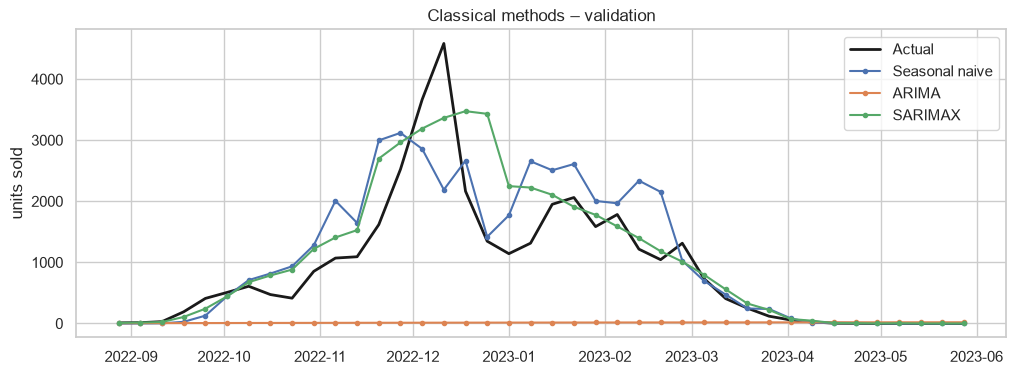

,MSE,RMSE,MAE,WAPE
SARIMAX,"307,184",554,317,34.7%
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%
ARIMA,"1,876,560","1,370",907,99.2%


In [14]:
plot_val(['Seasonal naive', 'ARIMA', 'SARIMAX'], 'Classical methods – validation')
results_table()

### 3.3 Conclusion

Le SARIMAX est le meilleur modèle à ce stade (MSE ≈ 307 000, −25 % par rapport au seasonal naive), car la courbe de
Fourier reproduit bien la montée et la descente de la saison. Le pic reste lissé : la semaine record (≈ 4 600) n'est
pas atteinte. Le test de sensibilité montre que le choix de d est crucial : avec d = 1, le total prévu varie de
≈ 12 000 à ≈ 117 000 selon les ventes d'une seule semaine d'août, contre ≈ 37 000 à 38 000 avec d = 0.

## 4. Machine learning

Les arbres apprennent une relation entre des features et les ventes de chaque semaine. Nous n'utilisons que des features
connues à l'avance, afin de prévoir les 40 semaines d'un coup :

| Feature | Description |
|---|---|
| `season_week` | semaines depuis le 1er septembre |
| `weeks_to_xmas` / `weeks_from_bf` | position par rapport à Noël et au Black Friday |
| `toussaint`, `noel`, `hiver` | vacances scolaires de la zone C |
| `log_stores` | log(1 + magasins avec ventes) |

Les ventes de l'année précédente ne sont pas utilisées, car elles n'existent pas pour la saison d'entraînement du fold.
Les hyperparamètres sont fixés a priori, car optimiser sur 50 semaines reviendrait à sur-ajuster le fold.

**Test de sur-apprentissage à partir d'ici.** Les modèles classiques ont ≈ 7 paramètres ; les arbres et le LSTM en ont
des centaines ou des milliers pour 50 semaines. Ils risquent donc de mémoriser la saison d'entraînement. Nous comparons
désormais la MSE d'entraînement à la MSE de validation : un ratio validation/train élevé signale un modèle qui a appris
par cœur.

In [15]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

HOLIDAYS = {
    'toussaint': [('2021-10-23', '2021-11-08'), ('2022-10-22', '2022-11-07'), ('2023-10-21', '2023-11-06')],
    'noel':      [('2021-12-18', '2022-01-03'), ('2022-12-17', '2023-01-03'), ('2023-12-23', '2024-01-08')],
    'hiver':     [('2022-02-19', '2022-03-07'), ('2023-02-18', '2023-03-06'), ('2024-02-10', '2024-02-26')],
}
BLACK_FRIDAYS = pd.to_datetime(['2021-11-26', '2022-11-25', '2023-11-24'])
ML_FEATURES = ['season_week', 'weeks_to_xmas', 'weeks_from_bf', 'toussaint', 'noel', 'hiver', 'log_stores']

def ml_features(df):
    d = df.index
    season_year = np.where(d.month >= 8, d.year, d.year - 1)
    X = pd.DataFrame(index=d)
    X['season_week'] = (d - pd.to_datetime([f'{y}-09-01' for y in season_year])).days // 7
    X['weeks_to_xmas'] = (pd.to_datetime([f'{y}-12-25' for y in season_year]) - d).days / 7
    bf = pd.to_datetime([BLACK_FRIDAYS[BLACK_FRIDAYS.year == y][0] for y in season_year])
    X['weeks_from_bf'] = (d - bf).days / 7
    for name, spans in HOLIDAYS.items():
        # la semaine va du dimanche `date` au samedi suivant
        X[name] = np.any([(d + pd.Timedelta(days=6) >= a) & (d <= b) for a, b in spans], axis=0).astype(int)
    X['log_stores'] = np.log1p(df.n_stores.values)
    return X[ML_FEATURES]

def ml_forecast(make_model, feature_fn=ml_features):
    def forecast(past, fut):
        model = make_model()
        model.fit(feature_fn(past), np.log1p(past.sales))
        forecast.model = model
        return pd.Series(np.expm1(model.predict(feature_fn(fut))), index=fut.index)
    return forecast

ml_features(val_future).head()

,season_week,weeks_to_xmas,weeks_from_bf,toussaint,noel,hiver,log_stores
date,,,,,,,
2022-08-28,-1,17.0,-12.714286,0,0,0,1.609438
2022-09-04,0,16.0,-11.714286,0,0,0,1.791759
2022-09-11,1,15.0,-10.714286,0,0,0,1.945910
2022-09-18,2,14.0,-9.714286,0,0,0,2.944439
2022-09-25,3,13.0,-8.714286,0,0,0,3.433987


`overfit_check` calcule la MSE d'entraînement et la compare à la MSE de validation.

In [16]:
overfit = {}       # MSE train vs validation par modèle

def overfit_check(name, forecast):
    fitted = forecast(val_train, val_train.drop(columns='sales')).clip(lower=0)
    mse_train, mse_val = metrics(val_train.sales, fitted)['MSE'], results[name]['MSE']
    overfit[name] = {'MSE train': mse_train, 'MSE validation': mse_val, 'ratio val / train': mse_val / mse_train}
    print(f'{name} | MSE train = {mse_train:,.0f} | MSE validation = {mse_val:,.0f} | ratio = {mse_val / mse_train:.1f}')

def overfit_table(names=None):
    df = pd.DataFrame(overfit).T
    df = df.loc[[n for n in (names or df.index) if n in df.index]]
    return df.style.format({'MSE train': '{:,.0f}', 'MSE validation': '{:,.0f}', 'ratio val / train': '{:.1f}'})

### 4.1 Random Forest

500 arbres moyennés pour réduire la variance ; `min_samples_leaf = 2` pour qu'aucune feuille ne repose sur une seule semaine.

In [17]:
rf_forecast = ml_forecast(lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=2,
                                                        random_state=42, n_jobs=-1))
evaluate('Random Forest', rf_forecast);
overfit_check('Random Forest', rf_forecast)

Random Forest | MSE = 368,001 | RMSE = 607 | MAE = 391 | WAPE = 0.427


Random Forest | MSE train = 30,029 | MSE validation = 368,001 | ratio = 12.3


### 4.2 XGBoost

Arbres construits successivement, chacun corrigeant les erreurs du précédent. `max_depth = 3` et un petit taux
d'apprentissage limitent le sur-apprentissage.

In [18]:
xgb_forecast = ml_forecast(lambda: XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=3,
                                                subsample=0.8, colsample_bytree=0.8, random_state=42))
evaluate('XGBoost', xgb_forecast);
overfit_check('XGBoost', xgb_forecast)

XGBoost | MSE = 371,109 | RMSE = 609 | MAE = 381 | WAPE = 0.416
XGBoost | MSE train = 7,412 | MSE validation = 371,109 | ratio = 50.1


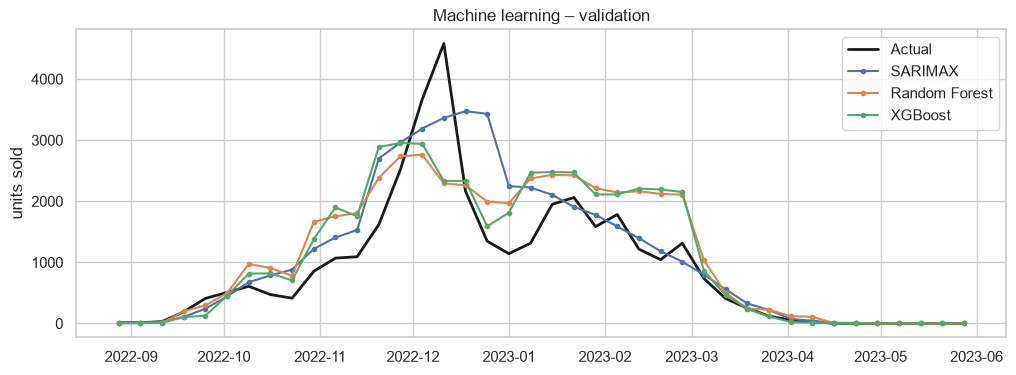

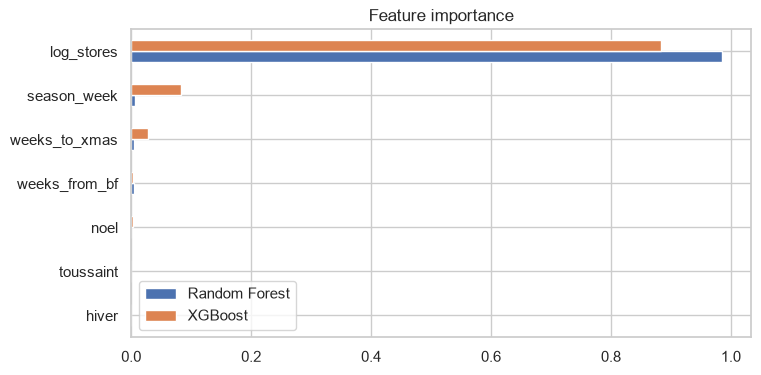

Total réel validation : 36,582
Total prévu Seasonal naive : 44,038
Total prévu SARIMAX        : 43,936
Total prévu Random Forest  : 45,518
Total prévu XGBoost        : 44,854


,MSE,RMSE,MAE,WAPE
SARIMAX,"307,184",554,317,34.7%
Random Forest,"368,001",607,391,42.7%
XGBoost,"371,109",609,381,41.6%
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%
ARIMA,"1,876,560","1,370",907,99.2%


In [19]:
plot_val(['SARIMAX', 'Random Forest', 'XGBoost'], 'Machine learning – validation')

# Importance des features (modèles entraînés sur le fold)
imp = pd.DataFrame({'Random Forest': rf_forecast.model.feature_importances_,
                    'XGBoost': xgb_forecast.model.feature_importances_}, index=ML_FEATURES)
imp.sort_values('Random Forest').plot.barh(figsize=(8, 4), title='Feature importance')
plt.show()

print('Total réel validation :', f'{y_val.sum():,.0f}')
for n in ['Seasonal naive', 'SARIMAX', 'Random Forest', 'XGBoost']:
    print(f'Total prévu {n:<15}: {val_preds[n].sum():,.0f}')
results_table()

Les deux modèles battent le seasonal naive (≈ 368 000 et ≈ 371 000) mais pas le SARIMAX. Le test de sur-apprentissage
l'explique : l'erreur d'entraînement est 12 à 50 fois plus faible que celle de validation, car les arbres reproduisent
la saison 2021-22 (pic fin novembre, creux de Noël) et l'appliquent à 2022-23.

### 4.3 Versions régularisées (modifications)

Les modèles d'origine sur-apprennent (ratios de 12 et 50). Nous appliquons trois modifications, définies avant de voir
les résultats :
1. **Features lisses** : `season_week`, `weeks_to_xmas` et `weeks_from_bf` permettent de mémoriser chaque semaine ; nous
   les remplaçons par une courbe annuelle (sinus/cosinus) et deux indicatrices (`pre_xmas`, `black_friday`).
2. **Modèles moins complexes** (4.3.1 et 4.3.2).
3. **Contrainte monotone** (XGBoost) : plus de magasins actifs ne peut pas faire baisser la prévision.

In [20]:
# Modification 1 – features lisses : courbe annuelle + indicatrices d'événements
ML_FEATURES_SMOOTH = ['sin_year', 'cos_year', 'pre_xmas', 'black_friday', 'toussaint', 'noel', 'hiver', 'log_stores']

def ml_features_smooth(df):
    X = ml_features(df)
    X['pre_xmas'] = ((X.weeks_to_xmas >= 0) & (X.weeks_to_xmas <= 5)).astype(int)
    X['black_friday'] = ((X.weeks_from_bf > -1) & (X.weeks_from_bf <= 0)).astype(int)   # semaine contenant le Black Friday
    X = X.join(fourier_terms(df.index, 1).rename(columns={'sin1': 'sin_year', 'cos1': 'cos_year'}))
    return X[ML_FEATURES_SMOOTH]

ml_features_smooth(val_future).iloc[10:16]

,sin_year,cos_year,pre_xmas,black_friday,toussaint,noel,hiver,log_stores
date,,,,,,,,
2022-11-06,-0.845050,0.534688,0,0,1,0,0,4.025352
2022-11-13,-0.774703,0.632326,0,0,0,0,0,3.988984
2022-11-20,-0.693136,0.720807,1,1,0,0,0,4.025352
2022-11-27,-0.601532,0.798849,1,0,0,0,0,4.025352
2022-12-04,-0.501216,0.865322,1,0,0,0,0,4.025352
2022-12-11,-0.393642,0.919264,1,0,0,1,0,4.025352


#### 4.3.1 Random Forest régularisé

`min_samples_leaf = 6` (au lieu de 2) pour que chaque feuille moyenne plusieurs semaines, et `max_depth = 4` pour
limiter la profondeur.

In [21]:
rf_reg_forecast = ml_forecast(lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=6, max_depth=4,
                                                            random_state=42, n_jobs=-1),
                              feature_fn=ml_features_smooth)
evaluate('Random Forest régularisé', rf_reg_forecast)
overfit_check('Random Forest régularisé', rf_reg_forecast)

Random Forest régularisé | MSE = 357,749 | RMSE = 598 | MAE = 361 | WAPE = 0.395


Random Forest régularisé | MSE train = 93,195 | MSE validation = 357,749 | ratio = 3.8


#### 4.3.2 XGBoost régularisé

`max_depth = 2`, `min_child_weight = 5` (au moins 5 semaines par division), pénalités L2 (`reg_lambda = 5`) et
L1 (`reg_alpha = 1`), et contrainte monotone croissante sur `log_stores`.

In [22]:
monotone = tuple(1 if f == 'log_stores' else 0 for f in ML_FEATURES_SMOOTH)
xgb_reg_forecast = ml_forecast(lambda: XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=2,
                                                    min_child_weight=5, reg_lambda=5, reg_alpha=1,
                                                    subsample=0.8, colsample_bytree=0.8,
                                                    monotone_constraints=monotone, random_state=42),
                               feature_fn=ml_features_smooth)
evaluate('XGBoost régularisé', xgb_reg_forecast)
overfit_check('XGBoost régularisé', xgb_reg_forecast)

XGBoost régularisé | MSE = 319,429 | RMSE = 565 | MAE = 339 | WAPE = 0.370
XGBoost régularisé | MSE train = 62,255 | MSE validation = 319,429 | ratio = 5.1


### 4.4 Comparaison : sur-apprentissage

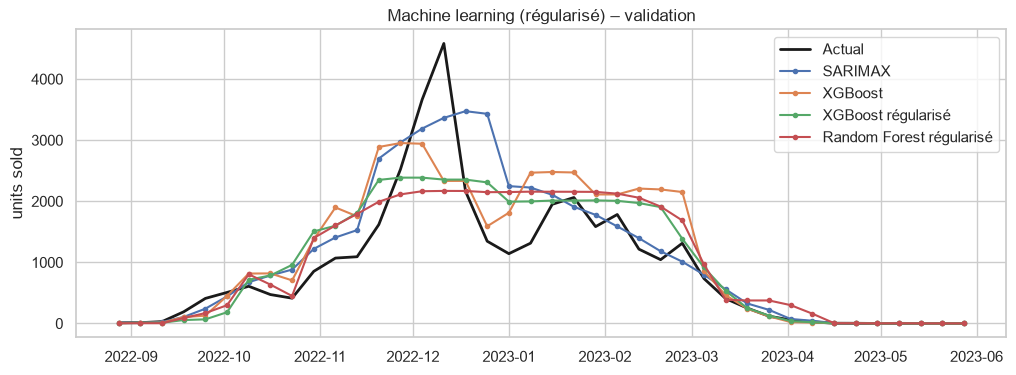

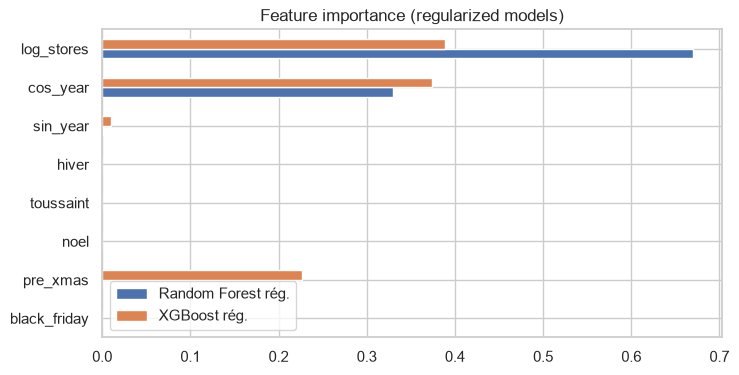

,MSE train,MSE validation,ratio val / train
Random Forest,"30,029","368,001",12.3
XGBoost,"7,412","371,109",50.1
Random Forest régularisé,"93,195","357,749",3.8
XGBoost régularisé,"62,255","319,429",5.1


In [23]:
plot_val(['SARIMAX', 'XGBoost', 'XGBoost régularisé', 'Random Forest régularisé'], 'Machine learning (régularisé) – validation')

imp = pd.DataFrame({'Random Forest rég.': rf_reg_forecast.model.feature_importances_,
                    'XGBoost rég.': xgb_reg_forecast.model.feature_importances_}, index=ML_FEATURES_SMOOTH)
imp.sort_values('Random Forest rég.').plot.barh(figsize=(8, 4), title='Feature importance (regularized models)')
plt.show()

display(overfit_table(['Random Forest', 'XGBoost', 'Random Forest régularisé', 'XGBoost régularisé']))

### 4.5 Conclusion

| Modèle | MSE train | MSE validation | Ratio |
|---|---|---|---|
| Random Forest | ≈ 30 000 | ≈ 368 000 | 12,3 |
| Random Forest régularisé | ≈ 93 000 | ≈ 358 000 | 3,8 |
| XGBoost | ≈ 7 000 | ≈ 371 000 | 50,1 |
| **XGBoost régularisé** | ≈ 62 000 | **≈ 319 000** | 5,1 |

La régularisation réduit fortement le sur-apprentissage et améliore la validation. Le XGBoost régularisé devient le
meilleur modèle de machine learning (−14 %) et se rapproche du SARIMAX. Le gain est faible pour le Random Forest, car
trop contraint il produit un plateau (≈ 2 200 unités) qui ne suit plus le pic. Avec les features lisses, les modèles
s'appuient sur la courbe annuelle plutôt que sur la position exacte de chaque semaine.

## 5. Deep learning simple

Réseaux de neurones entraînés sur les mêmes features que l'étape 4.

### 5.1 MLP

Perceptron multicouche sur les features de l'étape 4.

In [24]:
# TODO

### 5.2 LSTM

Un LSTM classique prédit la semaine suivante à partir des ventes passées ; ici, il reproduirait l'échec de l'ARIMA,
car la dernière semaine connue est toujours quasi nulle. Le réseau lit donc la séquence des features connues à
l'avance et produit les ventes de chaque semaine.

- Fenêtres de 40 semaines, la longueur de l'horizon à prévoir.
- 1 couche LSTM de 16 neurones, 300 époques sans early stopping, car le fold n'a pas de données de validation séparées.
- Moyenne de 5 réseaux (graines différentes), car un réseau seul est instable avec si peu de données.
- Une grille de sensibilité (fenêtre × neurones) vérifie que le résultat ne dépend pas d'un réglage particulier.

In [25]:
import torch
import torch.nn as nn
torch.set_num_threads(4)

class LSTMNet(nn.Module):
    def __init__(self, n_features, hidden, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)     # actif seulement en mode entraînement
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):                      # x : (batch, semaines, features)
        return self.head(self.dropout(self.lstm(x)[0])).squeeze(-1)

def make_lstm_forecast(window=40, hidden=16, epochs=300, n_seeds=5, lr=0.01, weight_decay=1e-4,
                       dropout=0.0, feature_fn=ml_features):
    def forecast(past, fut):
        X_past, X_fut = feature_fn(past), feature_fn(fut)
        mu, sd = X_past.mean(), X_past.std().replace(0, 1)
        X_past = ((X_past - mu) / sd).values.astype('float32')
        X_fut = ((X_fut - mu) / sd).values.astype('float32')
        y = np.log1p(past.sales.values).astype('float32')
        y_mu, y_sd = y.mean(), y.std()
        y_std = (y - y_mu) / y_sd

        starts = range(len(y) - window + 1)    # fenêtres glissantes de `window` semaines
        X_win = torch.tensor(np.stack([X_past[s:s + window] for s in starts]))
        y_win = torch.tensor(np.stack([y_std[s:s + window] for s in starts]))

        preds = []
        for seed in range(n_seeds):
            torch.manual_seed(seed)
            net = LSTMNet(X_past.shape[1], hidden, dropout)
            opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
            for _ in range(epochs):
                opt.zero_grad()
                loss = ((net(X_win) - y_win) ** 2).mean()
                loss.backward()
                opt.step()
            net.eval()
            with torch.no_grad():
                preds.append(net(torch.tensor(X_fut)[None])[0].numpy())
        log_pred = np.mean(preds, axis=0) * y_sd + y_mu
        return pd.Series(np.expm1(log_pred), index=fut.index)
    return forecast

lstm_forecast = make_lstm_forecast()
evaluate('LSTM', lstm_forecast)
overfit_check('LSTM', lstm_forecast)

LSTM | MSE = 362,768 | RMSE = 602 | MAE = 362 | WAPE = 0.396


LSTM | MSE train = 23,154 | MSE validation = 362,768 | ratio = 15.7


In [26]:
# Sensibilité aux hyperparamètres (longueur des fenêtres × taille de la couche cachée)
sens = []
for window in [13, 26, 40]:
    for hidden in [8, 16, 32]:
        pred = make_lstm_forecast(window=window, hidden=hidden)(val_train, val_future.drop(columns='sales')).clip(lower=0)
        sens.append({'fenêtre': window, 'neurones': hidden, 'MSE': metrics(y_val, pred)['MSE']})
pd.DataFrame(sens).pivot(index='fenêtre', columns='neurones', values='MSE').style.format('{:,.0f}')

neurones,8,16,32
fenêtre,,,
13,"398,963","395,068","390,106"
26,"401,314","372,017","378,054"
40,"405,715","362,768","364,182"


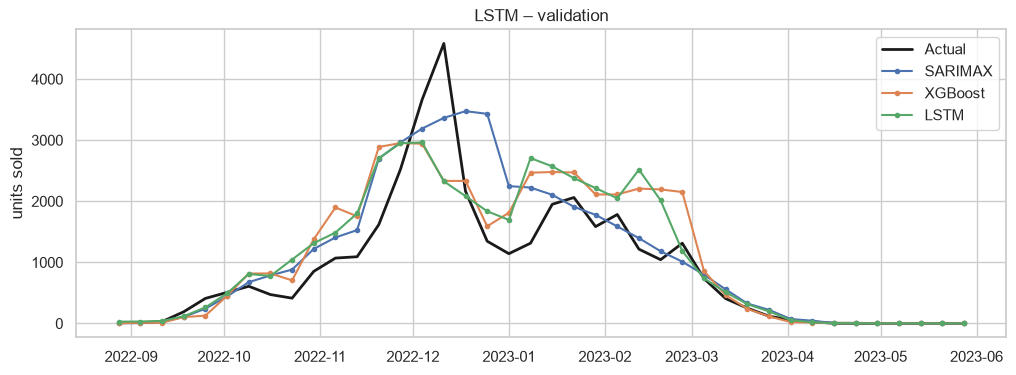

,MSE,RMSE,MAE,WAPE
SARIMAX,"307,184",554,317,34.7%
XGBoost régularisé,"319,429",565,339,37.0%
Random Forest régularisé,"357,749",598,361,39.5%
LSTM,"362,768",602,362,39.6%
Random Forest,"368,001",607,391,42.7%
XGBoost,"371,109",609,381,41.6%
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%
ARIMA,"1,876,560","1,370",907,99.2%


In [27]:
plot_val(['SARIMAX', 'XGBoost', 'LSTM'], 'LSTM – validation')
results_table()

Le LSTM bat le seasonal naive (≈ 363 000, −11 %) et se situe au niveau des arbres. Il sur-apprend aussi (ratio 15,7) :
comme eux, il copie le profil de 2021-22, y compris un rebond appris sur les vacances d'hiver 2022.

### 5.3 LSTM régularisé (modifications)

Mêmes principes qu'en 4.3 : features lisses, 8 neurones au lieu de 16, dropout de 0,3 (pour ne pas dépendre d'un
neurone précis), weight decay de 1e-3 au lieu de 1e-4 et 150 époques au lieu de 300. `LSTMNet` et `make_lstm_forecast`
ont reçu les paramètres `dropout` et `feature_fn`, sans changer le LSTM de 5.2.

In [28]:
lstm_reg_forecast = make_lstm_forecast(hidden=8, dropout=0.3, weight_decay=1e-3, epochs=150,
                                       feature_fn=ml_features_smooth)
evaluate('LSTM régularisé', lstm_reg_forecast)
overfit_check('LSTM régularisé', lstm_reg_forecast)

LSTM régularisé | MSE = 324,968 | RMSE = 570 | MAE = 304 | WAPE = 0.332


LSTM régularisé | MSE train = 58,458 | MSE validation = 324,968 | ratio = 5.6


### 5.4 Comparaison : sur-apprentissage

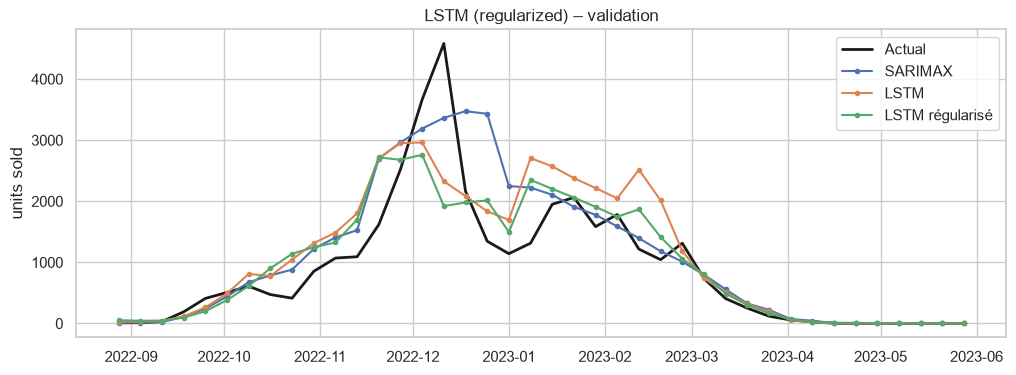

,MSE train,MSE validation,ratio val / train
LSTM,"23,154","362,768",15.7
LSTM régularisé,"58,458","324,968",5.6


In [29]:
plot_val(['SARIMAX', 'LSTM', 'LSTM régularisé'], 'LSTM (regularized) – validation')
display(overfit_table(['LSTM', 'LSTM régularisé']))

### 5.5 Conclusion

| Modèle | MSE train | MSE validation | Ratio |
|---|---|---|---|
| LSTM | ≈ 23 000 | ≈ 363 000 | 15,7 |
| LSTM régularisé | ≈ 58 000 | ≈ 325 000 | 5,6 |

La régularisation réduit le sur-apprentissage et améliore la validation (−10 %). Le LSTM reste derrière le SARIMAX. Cela s'explique par le
rapport entre paramètres (≈ 600 à 1 600) et données (50 semaines) : le deep learning a besoin de nombreux produits ou
d'un long historique, comme chez Decathlon en production.

## 6. Deep learning avancé

Nous testons les deux architectures présentées par Decathlon avec la bibliothèque `pytorch-forecasting`, pour
utiliser leurs implémentations de référence plutôt que des versions simplifiées.

- **Série unique** (total hebdomadaire) : un essai global sur les 55 magasins n'a rien amélioré (voir 6.3).
- **Encodeur de 4 semaines** : les modèles lisent les 4 dernières semaines de ventes, puis les variables connues
  à l'avance (`ml_features_smooth`, cf. 4.3) sur les semaines à prévoir.
- **Cible en log et perte MAE**, comme pour les autres modèles ; hyperparamètres fixés a priori ; moyenne de 3 graines.

In [30]:
import logging
import lightning.pytorch as pl
from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer, NHiTS
from pytorch_forecasting.metrics import MAE
from pytorch_forecasting.data import TorchNormalizer
for logger_name in ['lightning', 'lightning.pytorch', 'pytorch_lightning', 'lightning_fabric']:
    logging.getLogger(logger_name).setLevel(logging.ERROR)

def pf_frame(past, fut):
    df = pd.concat([past, fut.assign(sales=0.0)])   # ventes futures inconnues : remplies par 0, jamais lues
    X = ml_features_smooth(df)
    X['log_sales'] = np.log1p(df.sales.values)
    X['time_idx'] = np.arange(len(X))
    X['series'] = 'bonnet'
    return X.reset_index(drop=True)

def make_pf_forecast(kind, encoder_length=4, epochs=60, n_seeds=3, hidden=16, lr=0.01):
    def forecast(past, fut):
        df, H = pf_frame(past, fut), len(fut)
        fixed = kind == 'nhits'   # N-HiTS impose des fenêtres de longueur fixe
        train_ds = TimeSeriesDataSet(
            df.iloc[:len(past)], time_idx='time_idx', target='log_sales', group_ids=['series'],
            max_encoder_length=encoder_length, min_encoder_length=encoder_length if fixed else 2,
            max_prediction_length=H, min_prediction_length=H if fixed else 1,
            time_varying_known_reals=ML_FEATURES_SMOOTH, time_varying_unknown_reals=['log_sales'],
            target_normalizer=TorchNormalizer(), add_relative_time_idx=not fixed)
        forecast.n_windows = len(train_ds)
        pred_ds = TimeSeriesDataSet.from_dataset(train_ds, df, predict=True, stop_randomization=True)
        preds = []
        for seed in range(n_seeds):
            pl.seed_everything(seed, verbose=False)
            if kind == 'tft':
                model = TemporalFusionTransformer.from_dataset(
                    train_ds, hidden_size=hidden, attention_head_size=1, dropout=0.1,
                    hidden_continuous_size=8, loss=MAE(), learning_rate=lr, log_interval=-1)
            else:
                model = NHiTS.from_dataset(train_ds, hidden_size=hidden, dropout=0.1, loss=MAE(),
                                           learning_rate=lr, log_interval=-1)
            trainer = pl.Trainer(max_epochs=epochs, accelerator='cpu', enable_progress_bar=False, logger=False,
                                 enable_checkpointing=False, enable_model_summary=False, gradient_clip_val=0.1)
            trainer.fit(model, train_dataloaders=train_ds.to_dataloader(train=True, batch_size=16, num_workers=0))
            out = model.predict(pred_ds.to_dataloader(train=False, batch_size=1, num_workers=0), mode='prediction')
            preds.append(np.asarray(out).reshape(-1)[:H])
        return pd.Series(np.expm1(np.mean(preds, axis=0)), index=fut.index)
    return forecast

### 6.1 TFT (Temporal Fusion Transformer)

Le TFT sélectionne les variables utiles et utilise l'attention pour pondérer les semaines passées ; il est conçu pour
intégrer des variables connues à l'avance, comme notre calendrier. Nous autorisons des horizons de 1 à 40 semaines
pendant l'entraînement, car des fenêtres de 40 semaines fixes ne laisseraient que quelques exemples sur 50 semaines.

In [31]:
tft_forecast = make_pf_forecast('tft')
evaluate('TFT', tft_forecast)
print('Fenêtres d\'entraînement :', tft_forecast.n_windows)

C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\loops\training_epoch_loop.py:500: ReduceLROnPlateau conditioned on metric val_loss which is not available but strict is set to `False`. Skipping learning rate update.


C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\logger_connector\logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


TFT | MSE = 442,843 | RMSE = 665 | MAE = 416 | WAPE = 0.455
Fenêtres d'entraînement : 89


### 6.2 N-HiTS

Le N-HiTS décompose la prévision en plusieurs échelles de temps (tendance lente, variations rapides) par
interpolation hiérarchique. La bibliothèque impose des fenêtres de longueur fixe (4 + 40 semaines) : sur 50 semaines
d'entraînement, il ne reste que très peu de fenêtres.

In [32]:
nhits_forecast = make_pf_forecast('nhits')
evaluate('N-HiTS', nhits_forecast)
print('Fenêtres d\'entraînement :', nhits_forecast.n_windows)

C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py

C:\Users\debor\ECL\G3\ia et sante\partie IA\decathlon_forecast\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


N-HiTS | MSE = 1,890,247 | RMSE = 1,375 | MAE = 910 | WAPE = 0.995
Fenêtres d'entraînement : 7


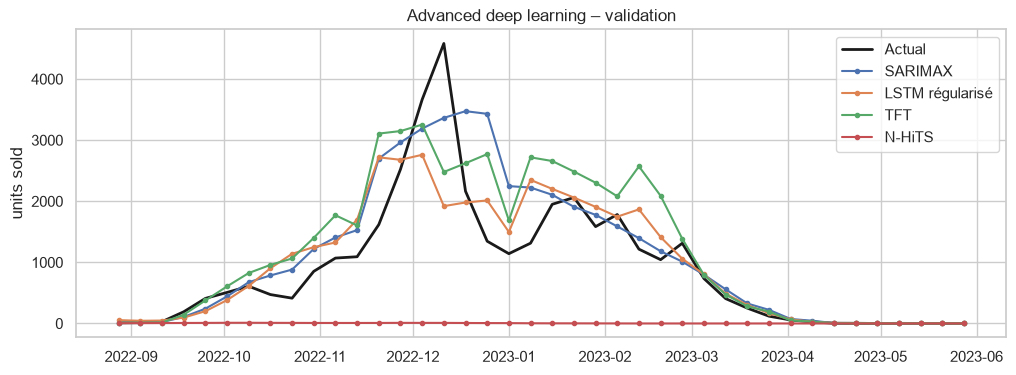

In [33]:
plot_val(['SARIMAX', 'LSTM régularisé', 'TFT', 'N-HiTS'], 'Advanced deep learning – validation')

### 6.3 Conclusion

| Modèle | MSE validation | WAPE | Fenêtres d'entraînement |
|---|---|---|---|
| Naïf saisonnier (référence) | ≈ 409 000 | 42,8 % | – |
| LSTM régularisé | ≈ 325 000 | 33,2 % | 11 |
| TFT | ≈ 443 000 | 45,5 % | 89 |
| N-HiTS | ≈ 1 890 000 | 99,5 % | 7 |

Aucune des deux architectures avancées ne bat la référence naïve. Le TFT reproduit le profil de la saison 2021-22 et
surestime janvier–février, car ses nombreux paramètres n'ont qu'une saison pour apprendre. Le N-HiTS prévoit ≈ 0 sur
toute la saison, car ses fenêtres fixes de 44 semaines ne laissent que 7 exemples d'entraînement. Un essai global sur
les 55 magasins (hors notebook, ≈ 385 et ≈ 4 900 fenêtres) ne les améliore pas : N-HiTS ≈ 1 575 000, TFT ≈ 507 000.
Ces modèles sont conçus pour de nombreuses séries longues ; sur un produit et deux saisons, les modèles simples et
structurés restent préférables.

## 7. Modèle préentraîné : Chronos-2

Chronos-2 (Amazon, 2025) est préentraîné sur un grand corpus de séries temporelles. Nous l'utilisons en **zéro-shot** :
aucun entraînement sur nos données, le modèle lit l'historique et prévoit directement. C'est la seule approche
avancée qui ne souffre pas de nos 50 semaines d'entraînement.

- Contexte = tout l'historique avant la date de prévision ; prévision = médiane (quantile 0,5).
- Cible = ventes brutes, car le modèle normalise lui-même chaque série.
- Pas de test de sur-apprentissage : le modèle n'est pas entraîné sur nos données.
- Deux variantes : historique seul (7.1) et avec les variables connues à l'avance (7.2), que Chronos-2 accepte.

In [34]:
from chronos import Chronos2Pipeline
chronos = Chronos2Pipeline.from_pretrained('amazon/chronos-2', device_map='cpu')   # téléchargé au premier appel

def make_chronos_forecast(covariates):
    def forecast(past, fut):
        context = pd.DataFrame({'item_id': 'bonnet', 'timestamp': past.index, 'target': past.sales.values})
        future_cov = None
        if covariates:
            context = pd.concat([context, ml_features_smooth(past).reset_index(drop=True)], axis=1)
            future_cov = pd.concat([pd.DataFrame({'item_id': 'bonnet', 'timestamp': fut.index}),
                                    ml_features_smooth(fut).reset_index(drop=True)], axis=1)
        out = chronos.predict_df(context, future_df=future_cov, prediction_length=len(fut), quantile_levels=[0.5])
        return pd.Series(out['predictions'].values, index=fut.index)
    return forecast

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

### 7.1 Chronos-2 sur l'historique seul

Version zéro-shot pure : le modèle ne voit que les ventes passées, comme l'ARIMA.

In [35]:
chronos_uni_forecast = make_chronos_forecast(covariates=False)
evaluate('Chronos-2', chronos_uni_forecast);

Chronos-2 | MSE = 1,110,671 | RMSE = 1,054 | MAE = 658 | WAPE = 0.719


### 7.2 Chronos-2 avec variables connues à l'avance

Mêmes variables lisses que les modèles régularisés (courbe annuelle, Black Friday, avant-Noël, vacances,
`log_stores`), fournies aussi sur les semaines à prévoir.

In [36]:
chronos_cov_forecast = make_chronos_forecast(covariates=True)
evaluate('Chronos-2 + covariables', chronos_cov_forecast);

Chronos-2 + covariables | MSE = 376,473 | RMSE = 614 | MAE = 388 | WAPE = 0.425


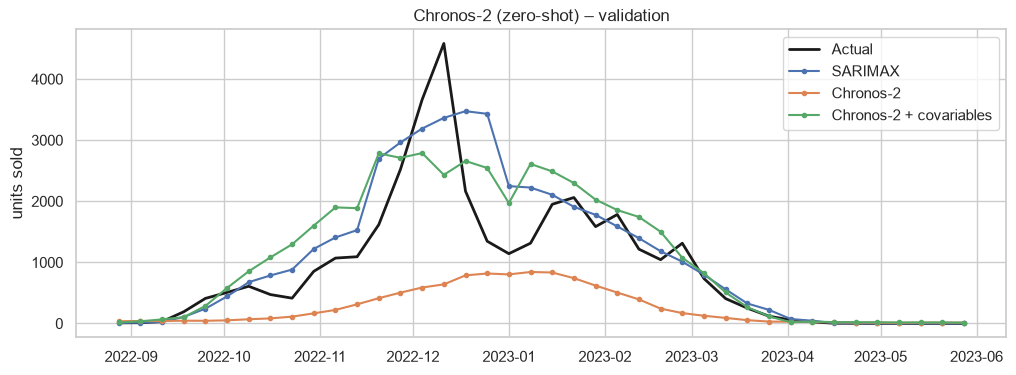

In [37]:
plot_val(['SARIMAX', 'Chronos-2', 'Chronos-2 + covariables'], 'Chronos-2 (zero-shot) – validation')

### 7.3 Conclusion

| Modèle | MSE validation | WAPE | Total prévu (réel : 36 582) |
|---|---|---|---|
| Naïf saisonnier (référence) | ≈ 409 000 | 42,8 % | 44 038 |
| Chronos-2 (historique seul) | ≈ 1 111 000 | 71,9 % | 10 577 |
| Chronos-2 + covariables | ≈ 376 000 | 42,5 % | 45 084 |
| SARIMAX | ≈ 307 000 | 34,7 % | 43 936 |

Sur l'historique seul, Chronos-2 échoue, car son contexte ne contient qu'une saison terminée par l'été : il prolonge
des ventes faibles et sous-estime la saison de 70 %. Avec les variables connues à l'avance, il bat la référence naïve
(−8 %) sans aucun entraînement et en moins d'une seconde, au niveau des arbres non régularisés, mais derrière le SARIMAX.
Le résultat est sensible à la transformation de la cible : en log (essai hors notebook), la MSE devient ≈ 420 000 sans
covariables et ≈ 682 000 avec. Le zéro-shot est donc une base rapide et prometteuse, mais pas encore fiable ici.

## 8. Machine learning par magasin

Jusqu'ici, tous les modèles prévoient directement le total. Ici, nous entraînons **un modèle par magasin** (55 modèles)
puis nous **additionnons leurs prévisions** pour obtenir le total hebdomadaire. Chaque magasin a son propre niveau de
ventes (EDA, section 3 : corrélation de 0,85 entre saisons), qu'un modèle dédié peut apprendre.

- Modèle : le **XGBoost régularisé** de 4.3.2 (meilleur modèle de machine learning), mêmes hyperparamètres et mêmes
  variables lisses, cible `log1p` des ventes du magasin.
- Un magasin sans aucune vente sur la période d'entraînement reçoit une prévision nulle.
- Deux variantes : sans (8.1) et avec (8.2) un indicateur d'activité propre au magasin.

In [38]:
# Ventes et activité (le magasin a une ligne cette semaine) par magasin et par semaine
all_dates = w.index
store_sales = train.pivot_table(index='date', columns='bu', values='sales_quantity', aggfunc='sum').reindex(all_dates).fillna(0)
store_active = (pd.concat([train, test]).assign(active=1)
                .pivot_table(index='date', columns='bu', values='active', aggfunc='max').reindex(all_dates).fillna(0))

def make_store_forecast(use_active):
    feats = ML_FEATURES_SMOOTH + (['active'] if use_active else [])
    monotone = tuple(1 if f in ('log_stores', 'active') else 0 for f in feats)
    def forecast(past, fut):
        X_past, X_fut = ml_features_smooth(past), ml_features_smooth(fut)
        total = np.zeros(len(fut))
        for bu in store_sales.columns:
            y = np.log1p(store_sales.loc[past.index, bu].values)
            if y.sum() == 0:
                continue
            Xp, Xf = X_past, X_fut
            if use_active:
                Xp = X_past.assign(active=store_active.loc[past.index, bu].values)
                Xf = X_fut.assign(active=store_active.loc[fut.index, bu].values)
            model = XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=2, min_child_weight=5,
                                 reg_lambda=5, reg_alpha=1, subsample=0.8, colsample_bytree=0.8,
                                 monotone_constraints=monotone, random_state=42, n_jobs=1)
            model.fit(Xp[feats], y)
            pred = np.expm1(model.predict(Xf[feats])).clip(0)
            if use_active:
                pred = pred * Xf.active.values   # pas de ligne cette semaine = pas de vente
            total += pred                        # somme des 55 magasins
        return pd.Series(total, index=fut.index)
    return forecast

### 8.1 XGBoost par magasin

Chaque magasin utilise les variables lisses communes (calendrier, `log_stores`).

In [39]:
store_forecast = make_store_forecast(use_active=False)
evaluate('XGBoost par magasin', store_forecast)
overfit_check('XGBoost par magasin', store_forecast)

XGBoost par magasin | MSE = 298,265 | RMSE = 546 | MAE = 317 | WAPE = 0.346


XGBoost par magasin | MSE train = 62,049 | MSE validation = 298,265 | ratio = 4.8


### 8.2 XGBoost par magasin + activité du magasin

Le fichier de test ne contient une ligne que si le magasin vend : nous savons donc, pour chaque magasin et chaque
semaine à prévoir, s'il sera actif. Nous ajoutons cet indicateur et forçons la prévision à 0 quand il vaut 0.

In [40]:
store_active_forecast = make_store_forecast(use_active=True)
evaluate('XGBoost par magasin + activité', store_active_forecast)
overfit_check('XGBoost par magasin + activité', store_active_forecast)

XGBoost par magasin + activité | MSE = 313,878 | RMSE = 560 | MAE = 322 | WAPE = 0.352


XGBoost par magasin + activité | MSE train = 69,567 | MSE validation = 313,878 | ratio = 4.5


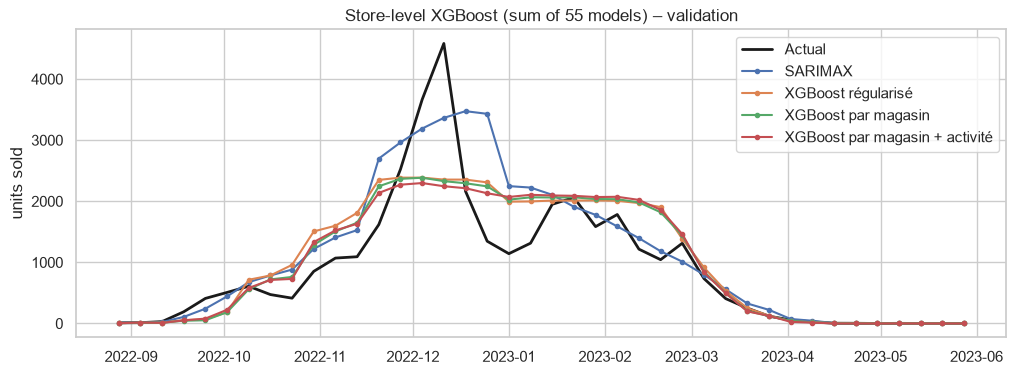

,MSE train,MSE validation,ratio val / train
XGBoost régularisé,"62,255","319,429",5.1
XGBoost par magasin,"62,049","298,265",4.8
XGBoost par magasin + activité,"69,567","313,878",4.5


In [41]:
plot_val(['SARIMAX', 'XGBoost régularisé', 'XGBoost par magasin', 'XGBoost par magasin + activité'],
         'Store-level XGBoost (sum of 55 models) – validation')
display(overfit_table(['XGBoost régularisé', 'XGBoost par magasin', 'XGBoost par magasin + activité']))

### 8.3 Conclusion

| Modèle | MSE train | MSE validation | Ratio | WAPE |
|---|---|---|---|---|
| XGBoost régularisé (total) | ≈ 62 000 | ≈ 319 000 | 5,1 | 37,0 % |
| **XGBoost par magasin** | ≈ 62 000 | **≈ 298 000** | 4,8 | 34,6 % |
| XGBoost par magasin + activité | ≈ 70 000 | ≈ 314 000 | 4,5 | 35,2 % |
| SARIMAX | – | ≈ 307 000 | – | 34,7 % |

La somme des 55 modèles par magasin donne la meilleure MSE de tous les modèles (−7 % par rapport au même XGBoost
entraîné sur le total, −3 % par rapport au SARIMAX), car chaque modèle apprend le niveau propre à son magasin. Le gain
reste modeste : la prévision garde la forme en plateau du XGBoost régularisé et ne reproduit pas le pic de décembre.
L'indicateur d'activité n'aide pas, car en pleine saison tous les magasins sont actifs : il vaut 1 précisément là où se
trouvent les erreurs, et n'apporte rien de plus que `log_stores`.

## 9. Comparaison des modèles

### 9.1 Tableau récapitulatif

In [42]:
display(results_table())
overfit_table()

,MSE,RMSE,MAE,WAPE
XGBoost par magasin,"298,265",546,317,34.6%
SARIMAX,"307,184",554,317,34.7%
XGBoost par magasin + activité,"313,878",560,322,35.2%
XGBoost régularisé,"319,429",565,339,37.0%
LSTM régularisé,"324,968",570,304,33.2%
Random Forest régularisé,"357,749",598,361,39.5%
LSTM,"362,768",602,362,39.6%
Random Forest,"368,001",607,391,42.7%
XGBoost,"371,109",609,381,41.6%
Chronos-2 + covariables,"376,473",614,388,42.5%


,MSE train,MSE validation,ratio val / train
Random Forest,"30,029","368,001",12.3
XGBoost,"7,412","371,109",50.1
Random Forest régularisé,"93,195","357,749",3.8
XGBoost régularisé,"62,255","319,429",5.1
LSTM,"23,154","362,768",15.7
LSTM régularisé,"58,458","324,968",5.6
XGBoost par magasin,"62,049","298,265",4.8
XGBoost par magasin + activité,"69,567","313,878",4.5


### 9.2 Choix final

*À compléter : choix du modèle final et justification.*